# The argument, step by step — Step 5: the pile-up's phase jitter

Fifth notebook; **one toggle — `confusion`**. Sources are not alone in their frequency bins.
Every comb's phase is read against the coherent sum of *everything else* in its $1/T$ bin —
the pile-up — and that crowd jitters the tooth pattern. Convention (campaign's Earth-side
pile-up, stated DEMO-glue): $\sigma_{\rm conf}=\sqrt{\sum_{j\ne k,\,{\rm bin}}h_j^2}\,/\,h_k$
in quadrature. The full population contributes — detected or not; being invisible to the
detector does not excuse a source from crowding the bin.

No sea, no red noise: this world isolates the tax the campaign writes as
$e^{-\sigma_\phi^2}$ — the coherence fraction $s<1$ arriving for the first time.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
import hasasia, hasasia.sim as hsim, hasasia.sensitivity as hsen
np.seterr(all="ignore")
plt.rcParams.update({"figure.dpi":110,"font.size":9,"axes.spines.top":False,
                     "axes.spines.right":False,"legend.frameon":False})
BLUE, RED, INK = "#2b5aa0", "#a03030", "0.35"
print("hasasia", hasasia.__version__)

PARAMS=dict(SEED=20260821, L_TRUE=1.42, SIGMA_D=2.0,
            N_PSR=120, SIGMA_TOA=100e-9, SIGMA_PSR=450e-9, CAD_D=14.0,
            SPANS=(5,10,15,20,25), RHO_DET=5.0, NSRC=3000,
            F_POP=(1e-9,3.0e-7), NREAL=200,
            C_PC_S=2.99792458e8/3.0856775814913673e16, YR_S=365.25*86400.0)
P=PARAMS; TOOTH=0.25
WORLD=dict(red_noise=False, gwb=False, confusion=True, loudness_structure=False)
print("WORLD toggles:", WORLD)

rng0=np.random.default_rng(P["SEED"])
freqs=np.logspace(np.log10(6e-10),-7,120)
_r=np.random.default_rng(42)
_phi=_r.uniform(0,2*np.pi,P["N_PSR"]); _th=np.arccos(_r.uniform(-1,1,P["N_PSR"]))
_CURVES={}
def curve(T):
    if T not in _CURVES:
        ps=hsim.sim_pta(timespan=float(T),cad=365.25/P["CAD_D"],sigma=P["SIGMA_TOA"],
                        phi=_phi,theta=_th,A_gwb=0,freqs=freqs)
        _CURVES[T]=hsen.DeterSensitivityCurve(
            [hsen.Spectrum(p,freqs=freqs) for p in ps]).h_c
    return _CURVES[T]

# ---- Faithful standalone port of active_wheel_demo_v4 cell 3 (V1): the NG15
# full-physics joint (Mc,z) population, ABSOLUTE normalisation, discrete tail.
G_SI,C_SI=6.674e-11,2.998e8
MSUN,MPC=1.989e30,3.086e22
YRV=3.15576e7
T_YR=30; T_OBS=T_YR*YRV; F_YR=1/YRV
ALPHA_F=-8/3; F_RANGE=(2e-10,1e-7); F_BEND=2e-9; MC_MIN=1e8*MSUN
A_NG15=6.4e-15; RATE_RESIDUAL=2.47
NG_PSI0,NG_MPSI0,NG_MU,NG_EPS=-2.0,11.4,8.60,0.30
NG_APSI0,NG_AMU,NG_FBULGE=-1.21,1.10,0.615
NG_P0,NG_BETP=0.033,1.0
NG_T0GYR,NG_BETT,NG_GAMT=0.5,-0.5,-1.0
NG_PSIZ,NG_MPSIZ,NG_APSIZ=-0.60,0.11,-0.03
KH=(8/np.sqrt(10))*G_SI**(5/3)*np.pi**(2/3)/C_SI**4
freqsV=np.logspace(np.log10(F_RANGE[0]),-7,100)
H0_SI=69.33*1e3/MPC
_zg=np.linspace(0,3.0,3001)
_Ez=np.sqrt(0.228*(1+_zg)**3+0.772)
_dcg=np.concatenate([[0],np.cumsum((C_SI/H0_SI)*0.5*(1/_Ez[1:]+1/_Ez[:-1])*np.diff(_zg))])
def d_com_m(z): return np.interp(z,_zg,_dcg)
def dt_dz(z): return 1.0/((1+z)*H0_SI*np.interp(z,_zg,_Ez))
_rngJ=np.random.default_rng(1234)
_lm1=np.linspace(9.5,13.2,190); _qs=np.linspace(0.25,1.0,26); _zs=np.linspace(0.02,2.0,55)
_LM1,_QS,_ZS=np.meshgrid(_lm1,_qs,_zs,indexing="ij")
_dlm,_dq,_dz=_lm1[1]-_lm1[0],_qs[1]-_qs[0],_zs[1]-_zs[0]
_Psi=np.log(10)*10**(NG_PSI0+NG_PSIZ*_ZS) \
     *(10**_LM1/10**(NG_MPSI0+NG_MPSIZ*_ZS))**(1+NG_APSI0+NG_APSIZ*_ZS) \
     *np.exp(-10**_LM1/10**(NG_MPSI0+NG_MPSIZ*_ZS))
_Pp=NG_P0*(1+_ZS)**NG_BETP
_Tg=NG_T0GYR*1e9*YRV*(1+_ZS)**NG_BETT*_QS**NG_GAMT
_eta=_Psi*_dlm*(_Pp/_Tg)*dt_dz(_ZS)*_dz*_dq
_kp=_eta>0
_LM1,_QS,_ZS,_eta=_LM1[_kp],_QS[_kp],_ZS[_kp],_eta[_kp]
_NSC=16
_LM1=np.repeat(_LM1,_NSC); _QS=np.repeat(_QS,_NSC); _ZS=np.repeat(_ZS,_NSC)
_eta=np.repeat(_eta/_NSC,_NSC)
_M1=10**(NG_MU+NG_AMU*np.log10(NG_FBULGE*10**_LM1/1e11)+_rngJ.normal(0,NG_EPS,_LM1.shape))
_qbh=_QS**NG_AMU
SRC_MC=(_M1*(_M1*_qbh))**0.6/(_M1*(1+_qbh))**0.2*MSUN
_kp=SRC_MC>=MC_MIN
SRC_MC=SRC_MC[_kp]; SRC_Z=_ZS[_kp]; _eta=_eta[_kp]
_dc_m=d_com_m(SRC_Z); SRC_DL=(1+SRC_Z)*_dc_m
_Ctau=(5/96)*(G_SI*SRC_MC/C_SI**3)**(-5/3)*np.pi**(-8/3)
_shell=4*np.pi*(C_SI/MPC)*(1+SRC_Z)*(_dc_m/MPC)**2
SRC_W=RATE_RESIDUAL*_eta*_Ctau*(1+SRC_Z)**(-8/3)*_shell
SRC_AMP=KH*(SRC_MC*(1+SRC_Z))**(5/3)/SRC_DL
bin_edges=np.arange(F_RANGE[0],F_RANGE[1],1/T_OBS)
bin_cent=0.5*(bin_edges[1:]+bin_edges[:-1])
n_per_bin=SRC_W.sum()*np.maximum(bin_cent,F_BEND)**ALPHA_F/(bin_cent*T_OBS)
_ordA=np.argsort(SRC_AMP); _ampS=SRC_AMP[_ordA]
_cwS=np.cumsum(SRC_W[_ordA]); _cwT=_cwS[-1]
# split & UL curves (V1 recipe: 200-psr deepest bar/10; H95 anchored shape)
def _raw(n,s,t,A,seed=42,cad=26):
    r=np.random.default_rng(seed)
    ps=hsim.sim_pta(timespan=t,cad=cad,sigma=s*1e-9,phi=r.uniform(0,2*np.pi,n),
                    theta=np.arccos(r.uniform(-1,1,n)),A_gwb=A,freqs=freqsV)
    return hsen.DeterSensitivityCurve([hsen.Spectrum(p,freqs=freqsV) for p in ps]).h_c
SNR_BAR=3.0
def det_curve(hc,bar=SNR_BAR): return bar*hc/np.sqrt(freqsV*T_OBS)
H_SPLIT=det_curve(_raw(200,100.0,T_YR,A_NG15))*10**(-0.5)/10.0
def h_split_of_f(f): return np.interp(f,freqsV,H_SPLIT)
_shape=_raw(67,100.0,15.0,A_NG15)/np.sqrt(freqsV*15*YRV)
H95=_shape*(8.0e-15/np.interp(6e-9,freqsV,_shape))
def h95_of_f(f): return np.interp(f,freqsV,H95)
def draw_population(seed=3):
    rng=np.random.default_rng(seed)
    hs=h_split_of_f(bin_cent)
    F,H,MCx=[],[],[]
    for k,fc in enumerate(bin_cent):
        amp_cut=hs[k]/fc**(2/3)
        j=np.searchsorted(_ampS,amp_cut)
        w_below=_cwS[j-1] if j>0 else 0.0
        p_above=1.0-w_below/_cwT
        n=rng.poisson(n_per_bin[k]*p_above)
        if n==0 or j>=len(_ampS): continue
        def _d(m):
            u=rng.uniform(w_below,_cwT,m); ii=_ordA[np.searchsorted(_cwS,u)]
            return ii, fc+(rng.uniform(0,1,m)-0.5)/T_OBS
        ii,fss=_d(n); hh=SRC_AMP[ii]*fss**(2/3)
        for _ in range(50):
            bad=hh>h95_of_f(fss)
            if not bad.any(): break
            i2,f2=_d(int(bad.sum())); ii[bad],fss[bad]=i2,f2
            hh[bad]=SRC_AMP[i2]*f2**(2/3)
        F.append(fss);H.append(hh);MCx.append(SRC_MC[ii])
    return np.concatenate(F),np.concatenate(H),np.concatenate(MCx)
f_src,h_src,mc_src=draw_population(3)
f_E,h_E=f_src,h_src
Mc=mc_src/MSUN
P["NSRC"]=len(f_E)
print(f"V1 population ported verbatim: {len(f_E):,} discrete sources above the split")
print(f"  (fidelity check: the frozen campaign notebook draws exactly 18,727)")

def rho_E(T):        # Earth-term ARRAY SNR (Hazboun+19 Eq. 79 convention)
    hc=curve(T)
    return (h_E/np.interp(f_E,freqs,hc))*np.sqrt(f_E*T*P["YR_S"])
def detected(T): return rho_E(T)>=P["RHO_DET"]

# the fixed pulsar: mu per source drawn once (fixed geometry); its timing noise
# is SIGMA_PSR -- detection uses the WHOLE array's best pulsars, ranging uses THIS one.
mu=np.arccos(np.random.default_rng(5000).uniform(-0.9,0.9,P["NSRC"]))
kap_all=2*np.pi*f_E*(1-np.cos(mu))/P["C_PC_S"]
GRID=np.linspace(-3*P["SIGMA_D"],3*P["SIGMA_D"],1601)
NMAX_COMB=30      # inventory cap: detection finds hundreds; only the strongest
                  # are usable rulers (the campaign machine's nmax, same logic)
print(f"fixed pulsar: sigma_d = {P['SIGMA_D']} pc, timing noise {P['SIGMA_PSR']*1e9:.0f} ns")
print(f"K is MEASURED per span below (participation ratio over null winners --")
print(f"the r4-adopted method; with a mixed coarse+fine inventory the coarsest-comb")
print(f"convention is no longer meaningful and is not used)")
print(f"detected at 25 yr: {int(detected(25).sum())} of {P['NSRC']} sources")

def detected_sea(T): raise RuntimeError('sea off in this world')
def hc_det_sea(T): raise RuntimeError('sea off in this world')


hasasia 1.2.3
WORLD toggles: {'red_noise': False, 'gwb': False, 'confusion': True, 'loudness_structure': False}


V1 population ported verbatim: 18,727 discrete sources above the split
  (fidelity check: the frozen campaign notebook draws exactly 18,727)
fixed pulsar: sigma_d = 2.0 pc, timing noise 450 ns
K is MEASURED per span below (participation ratio over null winners --
the r4-adopted method; with a mixed coarse+fine inventory the coarsest-comb
convention is no longer meaningful and is not used)


detected at 25 yr: 5110 of 18727 sources


In [2]:
def rho_P(T):    # single-pulsar pulsar-term SNR (campaign convention)
    nt=T*365.25/P["CAD_D"]
    return (h_E/(2*np.pi*f_E))*np.sqrt(nt/2)/P["SIGMA_PSR"]
def sea_bin_strain(f,T):
    # per-bin rms strain of the NG15-amplitude sea: h_c(f)/sqrt(fT)  [DEMO glue]
    return A_NG15*(f*YRV)**(-2/3)/np.sqrt(f*T*P["YR_S"])
def rn_strain(f):
    # intrinsic red noise as an equivalent strain: h_RN = A_RN (f/f_yr)^((3-gamma)/2)
    # (the campaign's sigma_RN = h_RN/h quadrature convention)
    return A_RN*(f*YRV)**((3-GAM_RN)/2)
_FSORT=np.argsort(f_E); _FS=f_E[_FSORT]
_HS2=np.concatenate([[0.0],np.cumsum(h_E[_FSORT]**2)])
def conf_sigma(T,idx):
    # pile-up: rms strain of the OTHER sources within +-1/(2T) of the comb, over own strain
    bw=1.0/(T*P["YR_S"])
    lo=np.searchsorted(_FS,f_E[idx]-bw/2); hi=np.searchsorted(_FS,f_E[idx]+bw/2)
    return np.sqrt(np.maximum(_HS2[hi]-_HS2[lo]-h_E[idx]**2,0.0))/h_E[idx]
def _sigma_of(world,T,d,rp):
    sg2=1.0/np.maximum(rp,1e-3)**2
    if world["gwb"]:       sg2=sg2+(sea_bin_strain(f_E[d],T)/h_E[d])**2
    if world["red_noise"]: sg2=sg2+(rn_strain(f_E[d])/h_E[d])**2
    if world["confusion"]: sg2=sg2+conf_sigma(T,d)**2
    return np.sqrt(sg2)
def inventory(world,T):
    # rank by POST-noise sigma (the campaign's nats ranking, nats = log(pi/sigma)).
    # With frequency-dependent noise the white-SNR ranking is the WRONG CURRENCY: it
    # keeps bright low-f combs the noise destroys and discards high-f combs the noise
    # barely touches -- the step-1 inventory lesson, caught again at this step.
    det=detected_sea(T) if world["gwb"] else detected(T)
    d=np.where(det)[0]; rp=rho_P(T)[d]
    ruler=2*np.pi/kap_all[d]<=6*P["SIGMA_D"]    # ruler condition (step 1, section 3)
    d=d[ruler]; rp=rp[ruler]
    sg=_sigma_of(world,T,d,rp)
    if world["loudness_structure"]:
        adm=rp>=3.0; d,rp,sg=d[adm],rp[adm],sg[adm]   # campaign admission cut
        o=np.argsort(sg)[:12]
    else:
        o=np.argsort(sg)[:NMAX_COMB]
    return d[o],rp[o]
def comb_sigmas(world,T):
    d,rp=inventory(world,T)
    return np.clip(_sigma_of(world,T,d,rp),0.05,None), kap_all[d]
def stack(world,T,seed,with_prior=True):
    sg,kk=comb_sigmas(world,T)
    ok=sg<np.pi; sg,kk=sg[ok],kk[ok]
    if len(sg)<2: return None,None,None
    r=np.random.default_rng(seed)
    eps=kk*P["L_TRUE"]+r.normal(0,sg)
    resid=(kk[:,None]*GRID[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
    S=-(resid**2/(2*sg[:,None]**2)).sum(0)
    if with_prior: S=S-GRID**2/(2*P["SIGMA_D"]**2)
    return S-S.max(),sg,kk
def mtruth(S):
    it=int(np.argmin(np.abs(GRID-P["L_TRUE"])))
    far=np.abs(GRID-P["L_TRUE"])>2*TOOTH
    return float(S[it]-S[far].max())
def null_bar(world,T,ntrial=300):
    sg,kk=comb_sigmas(world,T); ok=sg<np.pi; sg,kk=sg[ok],kk[ok]
    if len(sg)<2: return np.nan,np.nan
    marg=[];pos=[]
    for t in range(ntrial):
        r=np.random.default_rng(50_000+t)
        eps=r.uniform(0,2*np.pi,len(sg))
        resid=(kk[:,None]*GRID[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
        S=-(resid**2/(2*sg[:,None]**2)).sum(0)-GRID**2/(2*P["SIGMA_D"]**2); S-=S.max()
        ip=int(np.argmax(S)); far=np.abs(GRID-GRID[ip])>2*TOOTH
        marg.append(float(S[ip]-S[far].max()) if far.any() else np.inf)
        pos.append(float(GRID[ip]))
    e=np.arange(GRID[0],GRID[-1]+2*TOOTH,2*TOOTH)
    c,_=np.histogram(pos,bins=e); p=c/max(c.sum(),1)
    return float(np.percentile(marg,90)), float(1.0/np.sum(p**2))
def experiment(world,T):
    hits=[];margs=[]
    for t in range(P["NREAL"]):
        S,sg,kk=stack(world,T,1000+t)
        if S is None: return None
        ip=int(np.argmax(S))
        hits.append(abs(float(GRID[ip])-P["L_TRUE"])<=TOOTH)
        margs.append(mtruth(S))
    bar,Km=null_bar(world,T)
    return dict(T=T,ncomb=len(sg),purity=float(np.mean(hits)),
                margin=float(np.median(margs)),bar=bar,K=Km)
# step-1 (clean world) baseline, measured there and quoted as reference:
STEP1_REF={5:(24,11.64,10.34),10:(30,456.58,330.11),15:(30,612.21,531.91),
           20:(30,745.32,642.05),25:(30,838.47,741.16)}   # (combs, margin, bar)

## 1 — The crowd in each bin, measured

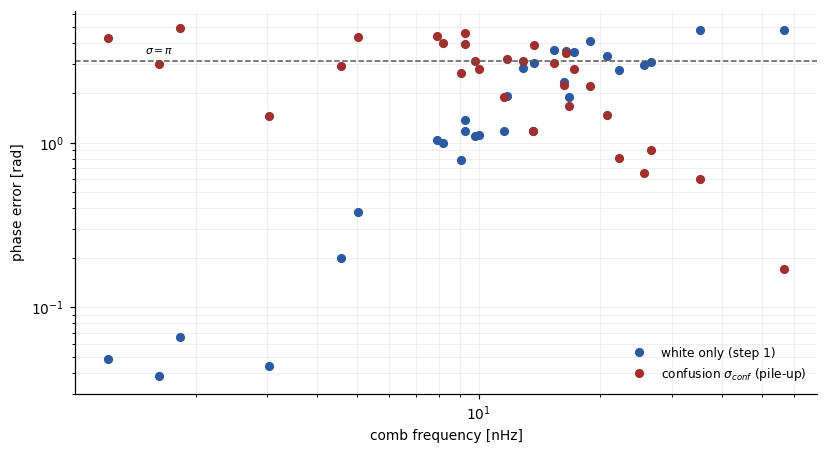

combs at 25 yr: 30
sigma_conf: median 2.85 rad, over pi for 10 combs
equivalent coherence s = 1/(1+sigma^2): median 0.110
(campaign banked: s_med = 0.434 at T = 60 on the full machine)


In [3]:
d,rp=inventory(WORLD,25)
sc=conf_sigma(25,d)
sg_w=1.0/np.maximum(rp,1e-3)
fig,ax=plt.subplots(figsize=(7.6,4.2))
ax.loglog(f_E[d]*1e9,sg_w,"o",color=BLUE,ms=5,label="white only (step 1)")
ax.loglog(f_E[d]*1e9,sc,"o",color=RED,ms=5,label="confusion $\\sigma_{conf}$ (pile-up)")
ax.axhline(np.pi,color=INK,lw=1,ls="--"); ax.text(1.5,np.pi*1.1,"$\\sigma=\\pi$",fontsize=7)
ax.set_xlabel("comb frequency [nHz]"); ax.set_ylabel("phase error [rad]")
ax.legend(fontsize=8); ax.grid(alpha=.25,lw=.5,which="both")
plt.tight_layout(); plt.show()
print(f"combs at 25 yr: {len(d)}")
print(f"sigma_conf: median {np.median(sc):.2f} rad, over pi for {int((sc>=np.pi).sum())} combs")
print(f"equivalent coherence s = 1/(1+sigma^2): median {np.median(1/(1+sc**2)):.3f}")
print(f"(campaign banked: s_med = 0.434 at T = 60 on the full machine)")

**Figure 1.** The pile-up against the white noise floor, comb by comb. Where the red points
sit above the blue, confusion — not instrument noise — owns that comb's phase; above
$\sigma=\pi$ the comb is a bystander. This is the pattern the campaign calls the funnel: the
crowd is thickest exactly where the combs are.

---

## 2 — Certification across spans, pile-up on

In [4]:
CSV_NAME="step5_scoreboard.csv"
import csv
rows=[]
print(f"{'T [yr]':>7} {'combs':>6} {'K_meas':>7} {'purity':>8} {'margin':>9} {'bar':>8}"
      f" {'verdict':>10} {'step-1 margin':>14}")
with open(CSV_NAME,"w",newline="") as fh:
    cw=csv.writer(fh)
    cw.writerow(["span_yr","n_combs","K_measured","purity","median_margin_nats",
                 "bar_nats","certifies","step1_margin_nats"])
    for T in P["SPANS"]:
        r=experiment(WORLD,T); ref=STEP1_REF[T]
        if r is None:
            d,rp=inventory(WORLD,T)
            sg,_=comb_sigmas(WORLD,T); nus=int((sg<np.pi).sum())
            print(f"{T:7d} {nus:6d} {'--':>7} {'--':>8} {'--':>9} {'--':>8}"
                  f" {'NO RULERS':>10} {ref[1]:+14.2f}")
            cw.writerow([T,nus,"","","","","NO_RULERS",f"{ref[1]:.3f}"]); continue
        v="CERTIFIES" if r["margin"]>r["bar"] else "FAILS"
        print(f"{r['T']:7d} {r['ncomb']:6d} {r['K']:7.1f} {r['purity']:8.3f}"
              f" {r['margin']:+9.2f} {r['bar']:8.2f} {v:>10} {ref[1]:+14.2f}")
        cw.writerow([r["T"],r["ncomb"],f"{r['K']:.1f}",f"{r['purity']:.4f}",
                     f"{r['margin']:.3f}",f"{r['bar']:.3f}",v,f"{ref[1]:.3f}"])
        rows.append(r)

 T [yr]  combs  K_meas   purity    margin      bar    verdict  step-1 margin


      5      1      --       --        --       --  NO RULERS         +11.64


     10      2     5.8    0.055     -0.49     0.15      FAILS        +456.58


     15      3     6.9    0.105     -0.61     0.52      FAILS        +612.21


     20      4     7.3    0.190     -0.87     0.65      FAILS        +745.32


     25     10     7.9    0.205     -1.19     1.00      FAILS        +838.47


**Scoreboard.** The $e^{-\sigma_\phi^2}$ tax in scoreboard form, against step 1's margins.
The direction with span is real — narrower $1/T$ bins thin the crowd, and the fair
post-confusion ranking (the campaign's nats currency; white-SNR ranking would pick the most
crowded combs) grows the usable inventory from 1 comb at 5 yr to 10 by 25 yr — yet the crowd
wins everywhere: no span certifies, and even the ten survivors decode the wrong tooth ~80 %
of the time. Confusion is the one ingredient time *would* fix in principle; the measured
rate says not on any calendar this series draws.

---

## 3 — The wheel in the crowd

In [5]:
# the same 120-pulsar array as step 1 (same seed 777 draws)
rngW=np.random.default_rng(777)
NPW=120
D_kpc=rngW.uniform(0.5,3.0,NPW)
sigd_j=np.clip(2.0*(D_kpc/1.5)**2,0.3,10.0)
Lt_j=np.clip(rngW.normal(0,sigd_j),-2.5*sigd_j,2.5*sigd_j)
sig_psr=10**rngW.normal(np.log10(250e-9),0.22,NPW)
mu_W=np.arccos(rngW.uniform(-0.9,0.9,(NPW,P["NSRC"])))
kap_W=2*np.pi*f_E[None,:]*(1-np.cos(mu_W))/P["C_PC_S"]
A_RN_j=(10**np.random.default_rng(778).normal(0,0.3,NPW))   # per-pulsar RN scatter (x A_RN)
def psr_sigma(world,T,j,di):
    nt=T*365.25/P["CAD_D"]
    rp=(h_E[di]/(2*np.pi*f_E[di]))*np.sqrt(nt/2)/sig_psr[j]
    sg2=1.0/np.maximum(rp,1e-3)**2
    if world["gwb"]:       sg2=sg2+(sea_bin_strain(f_E[di],T)/h_E[di])**2
    if world["red_noise"]: sg2=sg2+(A_RN_j[j]*rn_strain(f_E[di])/h_E[di])**2
    if world["confusion"]: sg2=sg2+conf_sigma(T,di)**2
    return np.clip(np.sqrt(sg2),0.05,None),rp
def psr_state(world,T,j,det,nreal=50,ntrial=100):
    nt=T*365.25/P["CAD_D"]
    rp_all=(h_E/(2*np.pi*f_E))*np.sqrt(nt/2)/sig_psr[j]
    di=np.where(det)[0]
    di=di[2*np.pi/kap_W[j][di]<=6*sigd_j[j]]
    sga,rpa=psr_sigma(world,T,j,di)              # post-noise sigma, all candidates
    if world["loudness_structure"]:
        adm=rpa>=3.0; di,sga=di[adm],sga[adm]
        o=np.argsort(sga)[:12]
    else:
        o=np.argsort(sga)[:NMAX_COMB]            # fair ranking (see inventory())
    di=di[o]
    sg,rp=psr_sigma(world,T,j,di)
    kk=kap_W[j][di]; ok=sg<np.pi; sg,kk=sg[ok],kk[ok]
    ncomb=len(sg)
    if ncomb<2: return False
    g=np.linspace(-3*sigd_j[j],3*sigd_j[j],1201)
    def one(eps):
        resid=(kk[:,None]*g[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
        S=-(resid**2/(2*sg[:,None]**2)).sum(0)-(g-0.0)**2/(2*sigd_j[j]**2)
        return S-S.max()
    margs=[]
    for t in range(nreal):
        r=np.random.default_rng(1000+t)
        S=one(kk*Lt_j[j]+r.normal(0,sg))
        it=int(np.argmin(np.abs(g-Lt_j[j])))
        far=np.abs(g-Lt_j[j])>2*TOOTH
        margs.append(float(S[it]-S[far].max()))
    bm=[]
    for t in range(ntrial):
        r=np.random.default_rng(50_000+t)
        S=one(r.uniform(0,2*np.pi,ncomb))
        ip=int(np.argmax(S)); far=np.abs(g-g[ip])>2*TOOTH
        bm.append(float(S[ip]-S[far].max()) if far.any() else np.inf)
    return float(np.median(margs))>float(np.percentile(bm,90))
def det_w(T,depth):
    hcw=hc_det_sea(T) if WORLD["gwb"] else curve(T)
    hcs=np.interp(f_E,freqs,hcw)
    return (h_E/hcs)*np.sqrt(f_E*T*P["YR_S"])*depth>=P["RHO_DET"]
T_W=25
det0=det_w(T_W,1.0)
cert=np.array([psr_state(WORLD,T_W,j,det0) for j in range(NPW)])
fc_hist=[cert.sum()/NPW]; det_hist=[det0.copy()]; depth_hist=[1.0]
prev=-1.0
while fc_hist[-1]>prev and len(fc_hist)<6:
    prev=fc_hist[-1]
    depth=10**(0.19*fc_hist[-1])
    det=det_w(T_W,depth)
    cert=np.array([psr_state(WORLD,T_W,j,det) for j in range(NPW)])
    fc_hist.append(cert.sum()/NPW); det_hist.append(det.copy()); depth_hist.append(depth)
print(f"WHEEL at T = {T_W} yr in this world")
print(f"  certified fraction through the turns: "+" -> ".join(f"{f:.3f}" for f in fc_hist))
print(f"  detection depth through the turns   : "+" -> ".join(f"x{d:.3f}" for d in depth_hist))
print(f"  sources detected: {int(det_hist[0].sum())} at turn 0 -> "
      f"{int(det_hist[-1].sum())} converged "
      f"(+{int((det_hist[-1]&~det_hist[0]).sum())} surfaced)")
print(f"  pulsars certified: {int(fc_hist[0]*NPW)} -> {int(fc_hist[-1]*NPW)} of {NPW}")
off=[int(sum(psr_state(WORLD,T,j,det_w(T,1.0)) for j in range(NPW))) for T in P["SPANS"]]
print(f"  baseline (wheel OFF) certified across spans "
      +", ".join(f"{T}yr:{n}" for T,n in zip(P["SPANS"],off)))
print(f"  [step-1 clean-world baseline: 5yr:93, 10yr:118, 15yr:112, 20yr:100, 25yr:100]")

WHEEL at T = 25 yr in this world
  certified fraction through the turns: 0.000 -> 0.000
  detection depth through the turns   : x1.000 -> x1.000
  sources detected: 5110 at turn 0 -> 5110 converged (+0 surfaced)
  pulsars certified: 0 -> 0 of 120


  baseline (wheel OFF) certified across spans 5yr:0, 10yr:0, 15yr:0, 20yr:0, 25yr:0
  [step-1 clean-world baseline: 5yr:93, 10yr:118, 15yr:112, 20yr:100, 25yr:100]


**Wheel verdict.** Zero pulsars certify at any span, so the loop never ignites — and note
the self-defeating structure it would face even if it did: every source the wheel surfaces is
another body in somebody's bin. In the campaign's full machine this is why the certification
face stayed shut ($b=0$) even when the detector face was real.

---

## 4 — Closing frame

Confusion **breaks the chain where it is strongest**: the evidence term itself. Unlike red
noise it cannot be selected away (every pulsar shares the sky), and unlike the sea it does not
announce itself on the detection curve — the combs are found, attributed, and *quietly wrong*.
The campaign's answer is the audited $\sigma_\phi$ and the coherence fraction $s$ carried
through every banked number.

**Next: step 6 — real priors**: the last ingredient is not noise at all. The window
$\sigma_d$ widens from 2 pc to the catalogue's hundreds, and the trials factor $c(p)\ln K$
does the rest.